In [6]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.6 (tags/v3.13.6:4e66535, Aug  6 2025, 14:36:00) [MSC v.1944 64 bit (AMD64)]
PyTorch: 2.8.0+cpu
Pandas: 2.3.1
NumPy: 2.3.2


In [7]:
# Locate the dataset relative to this notebook
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "household_power_consumption.txt"
)

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Load raw dataset
df = pd.read_csv(
    DATA_PATH,
    sep=";",
    low_memory=False
)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset path: c:\projects\Electricity-Forecasting-AD\data\raw\household_power_consumption.txt
Dataset exists: True

Dataset loaded successfully!
Dataset shape: (2075259, 9)


In [8]:
print("First 10 records:")
display(df.head(10))

print("\nLast 5 records:")
display(df.tail())

print("\nRandom 5 records:")
display(df.sample(5, random_state=42))

First 10 records:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
5,16/12/2006,17:29:00,3.520,0.522,235.020,15.000,0.000,2.000,17.0
6,16/12/2006,17:30:00,3.702,0.520,235.090,15.800,0.000,1.000,17.0
7,16/12/2006,17:31:00,3.700,0.520,235.220,15.800,0.000,1.000,17.0
8,16/12/2006,17:32:00,3.668,0.510,233.990,15.800,0.000,1.000,17.0
9,16/12/2006,17:33:00,3.662,0.510,233.860,15.800,0.000,2.000,16.0



Last 5 records:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075254,26/11/2010,20:58:00,0.946,0.000,240.430,4.000,0.000,0.000,0.0
2075255,26/11/2010,20:59:00,0.944,0.000,240.000,4.000,0.000,0.000,0.0
2075256,26/11/2010,21:00:00,0.938,0.000,239.820,3.800,0.000,0.000,0.0
2075257,26/11/2010,21:01:00,0.934,0.000,239.700,3.800,0.000,0.000,0.0
2075258,26/11/2010,21:02:00,0.932,0.000,239.550,3.800,0.000,0.000,0.0



Random 5 records:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
1870606,7/7/2010,18:10:00,0.256,0.106,242.000,1.200,0.000,0.000,1.0
213926,14/5/2007,06:50:00,0.466,0.352,237.220,2.400,0.000,2.000,0.0
409006,26/9/2007,18:10:00,0.758,0.194,238.660,3.200,0.000,1.000,0.0
265806,19/6/2007,07:30:00,1.290,0.046,240.640,5.400,1.000,0.000,18.0
1786279,10/5/2010,04:43:00,0.428,0.202,242.230,1.800,0.000,2.000,1.0


In [2]:
from pathlib import Path

DATA_PATH = Path("../data/raw/household_power_consumption.txt")

print("Dataset exists:", DATA_PATH.exists())

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset exists: True
Dataset loaded successfully!
Shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [9]:
print("Dataset information:")
df.info()

print("\nColumn data types:")
display(df.dtypes)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(8)
memory usage: 142.5+ MB

Column data types:


Date                      object
Time                      object
Global_active_power       object
Global_reactive_power     object
Voltage                   object
Global_intensity          object
Sub_metering_1            object
Sub_metering_2            object
Sub_metering_3           float64
dtype: object

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(8)
memory usage: 142.5+ MB


In [4]:
df.isna().sum()

Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64

In [10]:
# Count actual NaN values and question-mark placeholders
question_marks = (df == "?").sum()

df_check = df.replace("?", np.nan)

missing_count = df_check.isna().sum()

missing_percentage = (
    missing_count / len(df)
) * 100

missing_report = pd.DataFrame({
    "Question Mark Count": question_marks,
    "Total Missing": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_report)

,Question Mark Count,Total Missing,Missing Percentage
Date,0,0,0.000000
Time,0,0,0.000000
Global_active_power,25979,25979,1.251844
Global_reactive_power,25979,25979,1.251844
Voltage,25979,25979,1.251844
Global_intensity,25979,25979,1.251844
Sub_metering_1,25979,25979,1.251844
Sub_metering_2,25979,25979,1.251844
Sub_metering_3,0,25979,1.251844


In [11]:
print("First recorded date:", df["Date"].iloc[0])
print("Last recorded date:", df["Date"].iloc[-1])

print("\nTotal records:", len(df))

First recorded date: 16/12/2006
Last recorded date: 26/11/2010

Total records: 2075259


In [12]:
# Combine date and time
timestamps = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Calculate time difference between consecutive records
time_difference = timestamps.diff()

print("Most common time intervals:")
display(time_difference.value_counts().head(10))

print("\nInvalid timestamps:", timestamps.isna().sum())

Most common time intervals:


0 days 00:01:00    2075258
Name: count, dtype: int64


Invalid timestamps: 0


In [13]:
numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df_numeric = df.copy()

for column in numeric_columns:
    df_numeric[column] = pd.to_numeric(
        df_numeric[column].replace("?", np.nan),
        errors="coerce"
    )

print("Converted numerical columns.")

display(df_numeric[numeric_columns].describe().T)

Converted numerical columns.


,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000


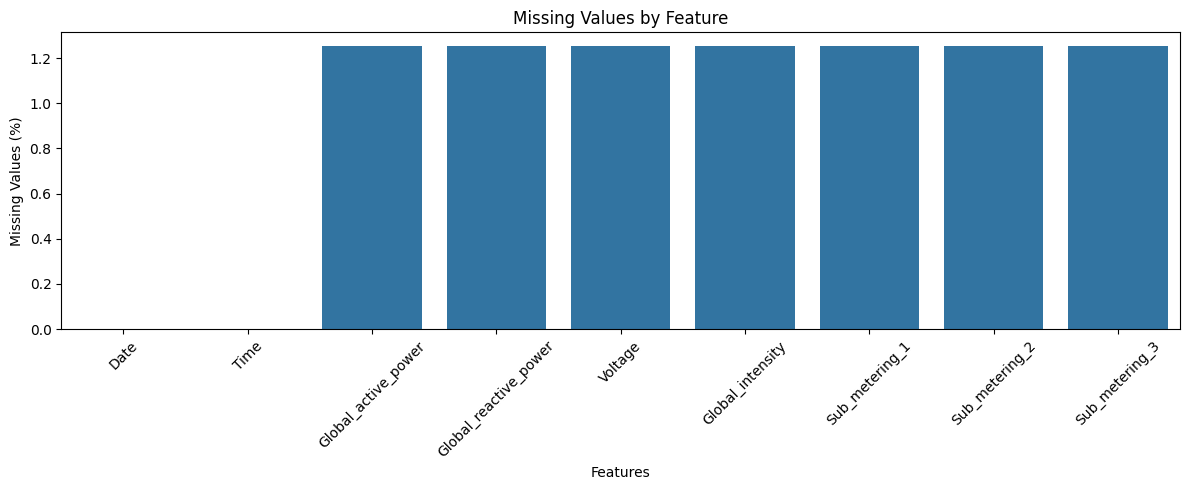

In [14]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing_report.index,
    y=missing_report["Missing Percentage"]
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

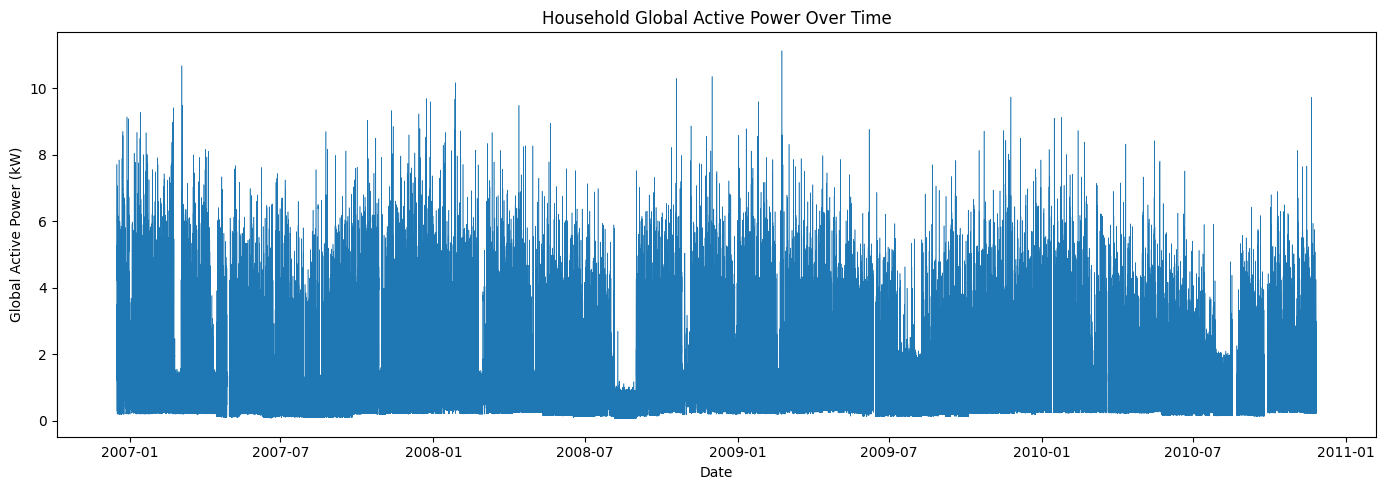

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    timestamps,
    df_numeric["Global_active_power"],
    linewidth=0.4
)

plt.title("Household Global Active Power Over Time")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.tight_layout()

plt.show()

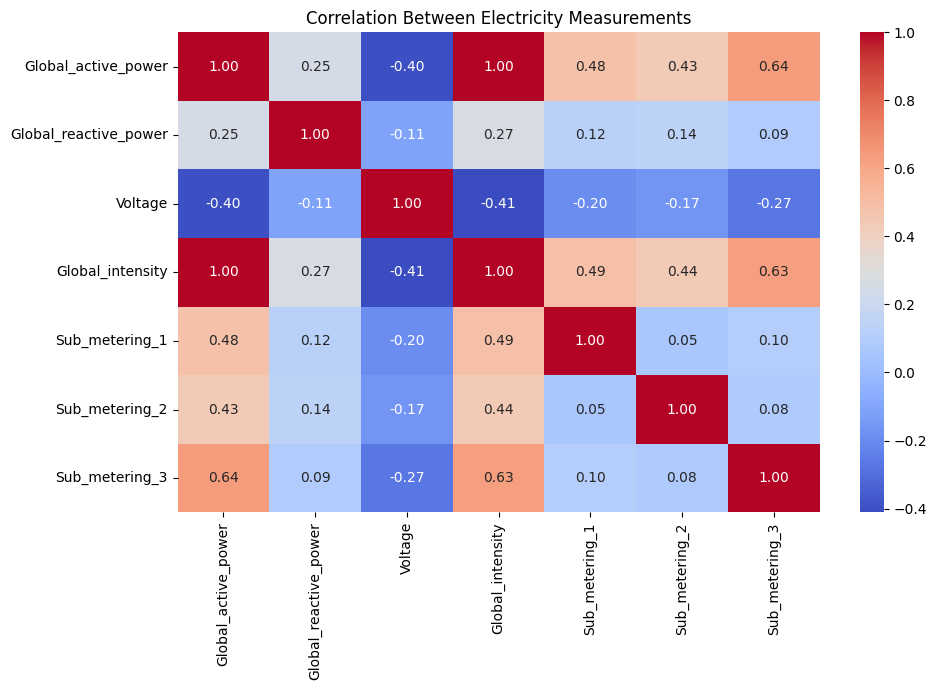

In [16]:
plt.figure(figsize=(10, 7))

correlation = df_numeric[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Electricity Measurements")
plt.tight_layout()

plt.show()

In [1]:
import sys

print("Notebook Python executable:")
print(sys.executable)

print("\nPyTorch version:")
print(torch.__version__)

Notebook Python executable:
c:\projects\Electricity-Forecasting-AD\newv\Scripts\python.exe

PyTorch version:


NameError: name 'torch' is not defined

In [2]:
import sys

print("Notebook Python executable:")
print(sys.executable)

print("\nPyTorch version:")
print(torch.__version__)

Notebook Python executable:
c:\projects\Electricity-Forecasting-AD\newv\Scripts\python.exe

PyTorch version:


NameError: name 'torch' is not defined

In [3]:
import sys
import torch

print("Notebook Python executable:")
print(sys.executable)

print("\nPyTorch version:")
print(torch.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

Notebook Python executable:
c:\projects\Electricity-Forecasting-AD\newv\Scripts\python.exe

PyTorch version:
2.15.0+cpu

CUDA available:
False
